## Apply feature importance analysis using Decision Trees by manually constructing a decision tree algorithm from scratch, computing Gini impurity or entropy values, and ranking features without using scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(42)
n = 1500
cgpa      = np.clip(rng.normal(7.0, 1.0, n), 4, 10)
aptitude  = np.clip(rng.normal(65, 15, n), 0, 100)
internships = np.minimum(rng.poisson(1.0, n), 4)
projects  = np.minimum(rng.poisson(2.0, n), 6)
comm      = np.clip(rng.normal(6, 1.5, n), 1, 10)
backlogs  = np.minimum(rng.poisson(0.5, n), 5)
roll_no   = rng.permutation(n) + 1                        
shoe_size = rng.integers(5, 12, n)                        
random_f  = rng.normal(size=n)                            

names = ['cgpa', 'aptitude', 'internships', 'projects', 'communication', 'backlogs',
         'roll_no', 'shoe_size', 'random_noise']
X = np.c_[cgpa, aptitude, internships, projects, comm, backlogs, roll_no, shoe_size, random_f]

logit = (1.2 * (cgpa - 7) + 0.04 * (aptitude - 65) + 0.5 * internships + 0.25 * projects
         + 0.15 * (comm - 6) - 0.6 * backlogs + 0.4 + rng.logistic(0, 0.5, n))   
y = (logit > 0).astype(int)

idx = rng.permutation(n); s = int(0.7 * n)
Xtr, ytr, Xte, yte = X[idx[:s]], y[idx[:s]], X[idx[s:]], y[idx[s:]]
print(Xtr.shape, Xte.shape, '| placed share:', y.mean().round(2))

(1050, 9) (450, 9) | placed share: 0.73


In [3]:
def impurity(counts, kind):
    p = counts / np.maximum(counts.sum(-1, keepdims=True), 1)
    if kind == 'gini':
        return 1 - (p ** 2).sum(-1)
    return -(np.where(p > 0, p * np.log2(np.where(p > 0, p, 1)), 0)).sum(-1)

def best_split(X, y, kind, min_leaf, n_classes):
    n, best = len(y), (None, None, 0.0)                     
    parent = impurity(np.bincount(y, minlength=n_classes), kind)
    onehot = np.eye(n_classes)[y]
    for f in range(X.shape[1]):
        order = np.argsort(X[:, f]); xs = X[order, f]
        cum = np.cumsum(onehot[order], axis=0)
        left, right = cum[:-1], cum[-1] - cum[:-1]            
        nl = np.arange(1, n)
        valid = (xs[:-1] != xs[1:]) & (nl >= min_leaf) & (n - nl >= min_leaf)   
        if not valid.any(): continue
        child = (nl / n) * impurity(left, kind) + ((n - nl) / n) * impurity(right, kind)
        gain = np.where(valid, parent - child, -1)
        i = int(np.argmax(gain))
        if gain[i] > best[2]:
            best = (f, (xs[i] + xs[i + 1]) / 2, gain[i])      
    return best

In [4]:
class DecisionTree:
    def __init__(self, criterion='gini', max_depth=None, min_samples_split=2, min_samples_leaf=1):
        self.kind, self.max_depth, self.mss, self.msl = criterion, max_depth, min_samples_split, min_samples_leaf

    def fit(self, X, y):
        self.n_total, self.k = len(y), int(y.max()) + 1
        self.importance = np.zeros(X.shape[1])
        self.root = self._grow(X, y, 0)
        self.importance /= max(self.importance.sum(), 1e-12)  
        return self

    def _grow(self, X, y, depth):
        counts = np.bincount(y, minlength=self.k)
        node = {'counts': counts, 'pred': int(counts.argmax()), 'n': len(y)}
        if (depth == self.max_depth or len(y) < self.mss or counts.max() == len(y)):
            return node                                        # leaf
        f, thr, gain = best_split(X, y, self.kind, self.msl, self.k)
        if f is None: return node
        self.importance[f] += len(y) / self.n_total * gain    
        m = X[:, f] <= thr
        node.update(f=f, thr=thr, left=self._grow(X[m], y[m], depth + 1), right=self._grow(X[~m], y[~m], depth + 1))
        return node

    def predict(self, X):
        out = np.empty(len(X), int)
        for i, x in enumerate(X):
            node = self.root
            while 'f' in node: node = node['left'] if x[node['f']] <= node['thr'] else node['right']
            out[i] = node['pred']
        return out

def accuracy(a, b): return np.mean(a == b)

def show(node, depth=0, max_show=3):
    pad = '  ' * depth
    if 'f' not in node or depth >= max_show:
        print(f"{pad}-> predict {node['pred']} (samples={node['n']}, counts={node['counts'].tolist()})"); return
    print(f"{pad}if {names[node['f']]} <= {node['thr']:.2f}:"); show(node['left'], depth + 1, max_show)
    print(f"{pad}else:"); show(node['right'], depth + 1, max_show)

In [5]:
trees = {k: DecisionTree(k, max_depth=5, min_samples_leaf=10).fit(Xtr, ytr) for k in ['gini', 'entropy']}
print('Majority baseline accuracy:', round(max(yte.mean(), 1 - yte.mean()), 3))
for k, t in trees.items():
    print(f'{k:8s} train acc = {accuracy(ytr, t.predict(Xtr)):.3f} | test acc = {accuracy(yte, t.predict(Xte)):.3f}')
print('\nGini tree (upar ke 3 levels):')
show(trees['gini'].root)

Majority baseline accuracy: 0.693
gini     train acc = 0.859 | test acc = 0.820
entropy  train acc = 0.858 | test acc = 0.818

Gini tree (upar ke 3 levels):
if cgpa <= 6.31:
  if internships <= 1.50:
    if aptitude <= 82.29:
      -> predict 0 (samples=160, counts=[124, 36])
    else:
      -> predict 1 (samples=22, counts=[7, 15])
  else:
    if aptitude <= 52.02:
      -> predict 0 (samples=11, counts=[9, 2])
    else:
      -> predict 1 (samples=54, counts=[14, 40])
else:
  if cgpa <= 7.05:
    if aptitude <= 62.36:
      -> predict 1 (samples=118, counts=[55, 63])
    else:
      -> predict 1 (samples=161, counts=[27, 134])
  else:
    if aptitude <= 48.28:
      -> predict 1 (samples=74, counts=[18, 56])
    else:
      -> predict 1 (samples=450, counts=[20, 430])


Feature         Gini imp.  Entropy imp.
cgpa                0.560         0.545
aptitude            0.197         0.250
internships         0.108         0.088
backlogs            0.060         0.059
communication       0.038         0.022
roll_no             0.020         0.012
projects            0.017         0.025
shoe_size           0.000         0.000
random_noise        0.000         0.000


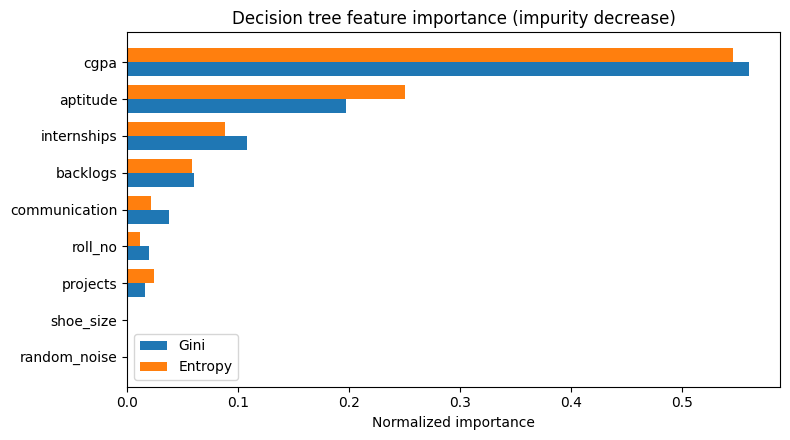

In [6]:
order = np.argsort(-trees['gini'].importance)
print(f"{'Feature':14s} {'Gini imp.':>10s} {'Entropy imp.':>13s}")
for i in order:
    print(f"{names[i]:14s} {trees['gini'].importance[i]:10.3f} {trees['entropy'].importance[i]:13.3f}")

pos = np.arange(len(names)); h = 0.38
plt.figure(figsize=(8, 4.5))
plt.barh(pos - h/2, trees['gini'].importance[order][::-1], h, label='Gini')
plt.barh(pos + h/2, trees['entropy'].importance[order][::-1], h, label='Entropy')
plt.yticks(pos, [names[i] for i in order][::-1]); plt.xlabel('Normalized importance')
plt.title('Decision tree feature importance (impurity decrease)'); plt.legend(); plt.tight_layout(); plt.show()

In [7]:
noise = [names.index(f) for f in ['roll_no', 'shoe_size', 'random_noise']]
print(f"{'max_depth':>9s} {'train acc':>10s} {'test acc':>9s} {'importance on 3 noise features':>32s}")
for d in [2, 3, 5, 8, None]:
    t = DecisionTree('gini', max_depth=d, min_samples_leaf=1 if d is None else 5).fit(Xtr, ytr)
    print(f"{str(d):>9s} {accuracy(ytr, t.predict(Xtr)):10.3f} {accuracy(yte, t.predict(Xte)):9.3f} {t.importance[noise].sum():32.3f}")

max_depth  train acc  test acc   importance on 3 noise features
        2      0.815     0.796                            0.000
        3      0.830     0.798                            0.000
        5      0.864     0.813                            0.033
        8      0.906     0.751                            0.106
     None      1.000     0.776                            0.133


In [8]:
def permutation_importance(tree, X, y, repeats=10, seed=0):
    r = np.random.default_rng(seed); base = accuracy(y, tree.predict(X)); drops = np.zeros((repeats, X.shape[1]))
    for j in range(X.shape[1]):
        for k in range(repeats):
            Xp = X.copy(); Xp[:, j] = r.permutation(Xp[:, j])
            drops[k, j] = base - accuracy(y, tree.predict(Xp))
    return drops.mean(0), drops.std(0)

pm, ps = permutation_importance(trees['gini'], Xte, yte)
print(f"{'Feature':14s} {'Impurity imp.':>14s} {'Permutation (acc drop)':>24s}")
for i in order:
    print(f"{names[i]:14s} {trees['gini'].importance[i]:14.3f} {pm[i]:14.3f} +- {ps[i]:.3f}")

Feature         Impurity imp.   Permutation (acc drop)
cgpa                    0.560          0.163 +- 0.015
aptitude                0.197          0.065 +- 0.009
internships             0.108          0.033 +- 0.014
backlogs                0.060          0.006 +- 0.006
communication           0.038          0.002 +- 0.004
roll_no                 0.020          0.003 +- 0.004
projects                0.017          0.002 +- 0.002
shoe_size               0.000          0.000 +- 0.000
random_noise            0.000          0.000 +- 0.000


Feature         Mean imp.     Std   In top-3 (30 runs)
cgpa                0.542   0.042                 100%
aptitude            0.182   0.038                  97%
internships         0.088   0.033                  60%
backlogs            0.052   0.031                  17%
communication       0.049   0.027                  10%
roll_no             0.032   0.023                  10%
random_noise        0.029   0.026                   7%
projects            0.015   0.018                   0%
shoe_size           0.012   0.016                   0%


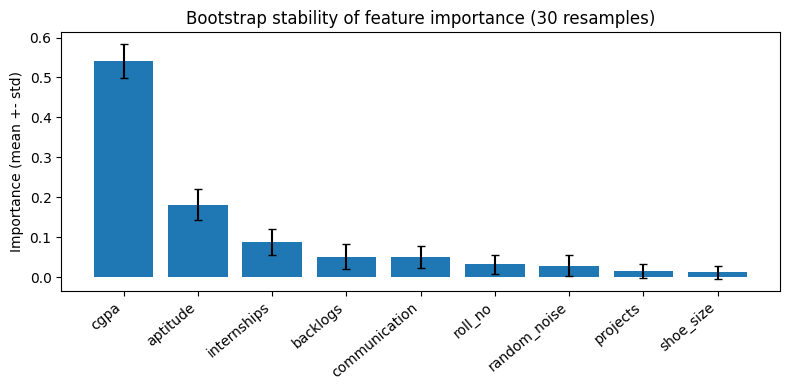

In [10]:
r = np.random.default_rng(7); boot = []
for _ in range(30):
    b = r.integers(0, len(ytr), len(ytr))
    boot.append(DecisionTree('gini', max_depth=5, min_samples_leaf=10).fit(Xtr[b], ytr[b]).importance)
boot = np.array(boot); mean, std = boot.mean(0), boot.std(0)
rank_freq = np.array([np.mean([j in np.argsort(-bi)[:3] for bi in boot]) for j in range(len(names))])  
print(f"{'Feature':14s} {'Mean imp.':>10s} {'Std':>7s} {'In top-3 (30 runs)':>20s}")
for i in np.argsort(-mean):
    print(f"{names[i]:14s} {mean[i]:10.3f} {std[i]:7.3f} {rank_freq[i]:20.0%}")

o = np.argsort(-mean)
plt.figure(figsize=(8, 4)); plt.bar([names[i] for i in o], mean[o], yerr=std[o], capsize=3, color='tab:blue')
plt.xticks(rotation=40, ha='right'); plt.ylabel('Importance (mean +- std)')
plt.title('Bootstrap stability of feature importance (30 resamples)'); plt.tight_layout(); plt.show()